# Solución del Parcial 1: puntos 1.5 y 2.4

**Curso:** Teoría de Aprendizaje de Máquina (2026-2)
**Tema:** métodos kernel, espacios de características y formulación matricial

**Alcance de este cuaderno**

| Punto | Qué se resuelve aquí |
| --- | --- |
| 1.5 | Implementación y comparación de mínimos cuadrados (MCO), mínimos cuadrados regularizados (ridge), máxima verosimilitud (MV) y máximo a posteriori (MAP) con $N = 300$, $P = 5$ y $Q = 20$. Se comparan las soluciones con tablas y gráficas. |
| 2.4 | Estimador empírico de $\text{MMD}^2$ con kernel gaussiano aplicado **solo a MNIST**: se comparan los primeros 500 datos con los segundos 500 datos, con visualización de las muestras, de las matrices de Gram y de la sensibilidad al ancho de banda. No se hace la comparación MNIST vs Fashion-MNIST. |

Los puntos 1.1 a 1.4 y 2.1 a 2.3 son desarrollos analíticos: aquí solo se usan sus resultados, que se citan en las celdas de teoría para que cada estimador quede justificado antes de codificarlo.

**Requisitos.** Python 3.10 a 3.13 con TensorFlow 2.x, NumPy y matplotlib. TensorFlow se usa **solo** para cargar MNIST (`tf.keras.datasets.mnist`); toda la parte numérica es NumPy y todas las gráficas son matplotlib. No se usa scikit-learn. La primera ejecución descarga MNIST en la caché de Keras (`~/.keras/datasets/`); después el cuaderno funciona sin red.

En la primera celda TensorFlow imprime un par de líneas de aviso (`Could not find cuda drivers on your machine, GPU will not be used`). Son normales: el runtime busca GPU, no la encuentra y trabaja en CPU, que es todo lo que este cuaderno necesita.

**Cómo ejecutar.** Abrir el cuaderno y ejecutar todas las celdas en orden. Las gráficas se muestran dentro del cuaderno; no se escribe ningún archivo.

**Recorrido:** entorno → 1.5 datos y diseño de $\Phi$ → 1.5 los cuatro estimadores → 1.5 métricas, diagnóstico y gráficas → 2.4 datos de MNIST en dos grupos de 500 → 2.4 kernel gaussiano y ancho de banda → 2.4 $\text{MMD}^2$, matrices de Gram, sensibilidad, variabilidad y conclusiones.

## 0. Entorno de trabajo

Se fija una única semilla para todo el cuaderno: los datos del punto 1.5 y la partición de MNIST del punto 2.4 usan el mismo generador, así que el cuaderno es reproducible de punta a punta.

TensorFlow se importa solo para acceder a MNIST. El nivel de log se baja a `3` para que la carga no llene la salida con avisos del runtime.

In [1]:
import os
import sys

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # sin avisos del runtime antes de importar

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEMILLA = 2026

print("Python:     ", sys.version.split()[0])
print("NumPy:      ", np.__version__)
print("TensorFlow: ", tf.__version__)
print("matplotlib: ", plt.matplotlib.__version__)
print("Semilla:    ", SEMILLA)

I0000 00:00:1794329736.343457   27832 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794329738.107444   27832 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python:      3.12.16
NumPy:       2.5.4
TensorFlow:  2.21.0
matplotlib:  3.11.2
Semilla:     2026


## 1.5.1. Datos y diseño del mapeo $\Phi$

El modelo es $t_n = \phi(x_n)^\top w + \eta_n$ con $x_n \in \mathbb{R}^P$, $w \in \mathbb{R}^Q$, $\Phi \in \mathbb{R}^{N \times Q}$ y $t \in \mathbb{R}^N$. Los parámetros del enunciado son $N = 300$, $P = 5$ y $Q = 20$.

**Generación de los datos** (semilla fija, en este orden):

1. Las filas de $X \in \mathbb{R}^{300 \times 5}$ son i.i.d. con entradas $\mathcal{N}(0, 1)$.
2. $\Phi(X) \in \mathbb{R}^{300 \times 20}$ concatena, en este orden:
   - columnas 0 a 4: las 5 columnas originales $x_1, \dots, x_5$;
   - columnas 5 a 9: sus cuadrados $x_1^2, \dots, x_5^2$;
   - columnas 10 a 19: los $\binom{5}{2} = 10$ productos por pares de columnas distintas, en orden lexicográfico: $x_1x_2, x_1x_3, x_1x_4, x_1x_5, x_2x_3, x_2x_4, x_2x_5, x_3x_4, x_3x_5, x_4x_5$.
3. $w^\ast \in \mathbb{R}^{20}$ con entradas i.i.d. $\mathcal{N}(0, 1)$ y $\eta_n \sim \mathcal{N}(0, 0.5^2)$ independientes, es decir $\sigma_\eta = 0.5$.
4. $t = \Phi(X)\,w^\ast + \eta$ con $t \in \mathbb{R}^{300}$.

**Partición.** Se separa aleatoriamente el 80 % para entrenamiento (240 filas) y el 20 % para prueba (60 filas). Los cuatro estimadores se ajustan **solo** con entrenamiento.

In [2]:
rng = np.random.default_rng(SEMILLA)

N, P, Q = 300, 5, 20

# 1. Filas de X i.i.d. con entradas N(0, 1): X (300, 5).
X = rng.normal(0.0, 1.0, size=(N, P))

# 2. Phi(X) (300, 20): originales, cuadrados y productos por pares distintos.
nombres = [f"x{j + 1}" for j in range(P)]
nombres += [f"x{j + 1}^2" for j in range(P)]
nombres += [f"x{i + 1}*x{j + 1}" for i in range(P) for j in range(i + 1, P)]

columnas = [X[:, j] for j in range(P)]
columnas += [X[:, j] ** 2 for j in range(P)]
columnas += [X[:, i] * X[:, j] for i in range(P) for j in range(i + 1, P)]
Phi = np.column_stack(columnas)

print("X:", X.shape, " Phi:", Phi.shape, " numero de columnas:", len(nombres))
print("orden de las 20 columnas de Phi:")
for k, nombre in enumerate(nombres):
    print(f"  columna {k:2d}: {nombre}")

X: (300, 5)  Phi: (300, 20)  numero de columnas: 20
orden de las 20 columnas de Phi:
  columna  0: x1
  columna  1: x2
  columna  2: x3
  columna  3: x4
  columna  4: x5
  columna  5: x1^2
  columna  6: x2^2
  columna  7: x3^2
  columna  8: x4^2
  columna  9: x5^2
  columna 10: x1*x2
  columna 11: x1*x3
  columna 12: x1*x4
  columna 13: x1*x5
  columna 14: x2*x3
  columna 15: x2*x4
  columna 16: x2*x5
  columna 17: x3*x4
  columna 18: x3*x5
  columna 19: x4*x5


In [3]:
# 3. w* ~ N(0, 1)^20 y ruido eta ~ N(0, 0.5^2) independiente.
w_estrella = rng.normal(0.0, 1.0, size=Q)
sigma_eta = 0.5
eta = rng.normal(0.0, sigma_eta, size=N)

# 4. Respuesta observada.
t = Phi @ w_estrella + eta

print("w*:", w_estrella.shape, " eta:", eta.shape, " t:", t.shape)
print("desviacion estandar empirica de eta:", eta.std(ddof=1).round(4), "(teorica 0.5)")

w*: (20,)  eta: (300,)  t: (300,)
desviacion estandar empirica de eta: 0.5223 (teorica 0.5)


In [4]:
# Particion 80 % entrenamiento / 20 % prueba (misma semilla, indices permutados).
indices = rng.permutation(N)
n_entrenamiento = int(0.8 * N)

idx_ent, idx_pru = indices[:n_entrenamiento], indices[n_entrenamiento:]
Phi_ent, Phi_pru = Phi[idx_ent], Phi[idx_pru]
t_ent, t_pru = t[idx_ent], t[idx_pru]

print("entrenamiento:", Phi_ent.shape, "->", n_entrenamiento, "filas")
print("prueba:       ", Phi_pru.shape, "->", N - n_entrenamiento, "filas")
print("filas repetidas entre ambos conjuntos:", len(np.intersect1d(idx_ent, idx_pru)))

entrenamiento: (240, 20) -> 240 filas
prueba:        (60, 20) -> 60 filas
filas repetidas entre ambos conjuntos: 0


## 1.5.2. Los cuatro estimadores en forma cerrada

Todos parten de la misma matriz de diseño de entrenamiento $\Phi_{\text{ent}} \in \mathbb{R}^{240 \times 20}$ y del vector $t_{\text{ent}} \in \mathbb{R}^{240}$.

**1. Mínimos cuadrados (MCO).** $J(w) = \lVert t - \Phi w \rVert_2^2$. Al derivar se obtienen las ecuaciones normales $\Phi^\top \Phi \, \hat{w} = \Phi^\top t$, y si $\operatorname{rango}(\Phi) = Q$ la solución es única: $\hat{w}_{\text{mco}} = (\Phi^\top \Phi)^{-1} \Phi^\top t$.

**2. Mínimos cuadrados regularizados (ridge).** $J(w) = \lVert t - \Phi w \rVert_2^2 + \lambda \lVert w \rVert_2^2$ con $\lambda > 0$, de donde $(\Phi^\top \Phi + \lambda I_Q) \, \hat{w} = \Phi^\top t$. La matriz $\Phi^\top \Phi + \lambda I_Q$ es definida positiva aunque $\Phi$ no tenga rango completo, así que la solución siempre existe y es única.

**3. Máxima verosimilitud (MV).** Con $\eta_n \sim \mathcal{N}(0, \sigma_\eta^2)$ i.i.d. se tiene $t \mid \Phi, w \sim \mathcal{N}(\Phi w, \sigma_\eta^2 I_N)$ y

$$\ell(w) = -\frac{N}{2}\log(2\pi\sigma_\eta^2) - \frac{1}{2\sigma_\eta^2}\lVert t - \Phi w \rVert_2^2 .$$

El único término que depende de $w$ es $-\lVert t - \Phi w \rVert_2^2 / (2\sigma_\eta^2)$, así que maximizar $\ell$ es minimizar $\lVert t - \Phi w \rVert_2^2$: MV conduce **a las mismas ecuaciones normales que MCO**, o sea $\hat{w}_{\text{mv}} = \hat{w}_{\text{mco}}$. El estimador de la varianza es $\hat{\sigma}_\eta^2 = \lVert t - \Phi \hat{w} \rVert_2^2 / N$.

**4. Máximo a posteriori (MAP).** Con el prior $w \sim \mathcal{N}(0, \sigma_w^2 I_Q)$, la regla de Bayes da

$$p(w \mid t) \propto \exp\left(-\frac{1}{2\sigma_\eta^2}\lVert t - \Phi w \rVert_2^2 - \frac{1}{2\sigma_w^2}\lVert w \rVert_2^2\right),$$

y maximizar el logaritmo equivale a minimizar $\lVert t - \Phi w \rVert_2^2 + \frac{\sigma_\eta^2}{\sigma_w^2}\lVert w \rVert_2^2$. Por lo tanto MAP es **exactamente ridge con** $\lambda = \sigma_\eta^2 / \sigma_w^2$.

**Valores del enunciado.** Se usa $\lambda = 1$ y el prior compatible $\sigma_w^2 = \sigma_\eta^2 / \lambda = 0.25 / 1 = 0.25$, es decir $\sigma_w = 0.5$. Con esos valores $\lambda$ y $\sigma_\eta^2/\sigma_w^2$ coinciden, como debe ser.

In [5]:
lam = 1.0                                  # penalizacion del ridge del enunciado
sigma_w = np.sqrt(sigma_eta ** 2 / lam)    # prior compatible: sigma_w^2 = sigma_eta^2 / lam
sigma_w2 = sigma_w ** 2

G = Phi_ent.T @ Phi_ent                    # (20, 20) = Phi_ent^T Phi_ent
b = Phi_ent.T @ t_ent                      # (20,)    = Phi_ent^T t_ent
I = np.eye(Q)                              # (20, 20)

# 1. MCO: ecuaciones normales.
w_mco = np.linalg.solve(G, b)

# 2. Ridge: penalizacion cuadrática lam * ||w||^2.
w_ridge = np.linalg.solve(G + lam * I, b)

# 3. MV: mismas ecuaciones normales, resueltas por otra via numerica (SVD via lstsq)
#    para comprobar que el resultado es el mismo y no un copiado del anterior.
w_mv = np.linalg.lstsq(Phi_ent, t_ent, rcond=None)[0]
sigma_eta2_mv = np.sum((t_ent - Phi_ent @ w_mv) ** 2) / n_entrenamiento

# 4. MAP: ridge con lam = sigma_eta^2 / sigma_w^2.
lam_map = sigma_eta ** 2 / sigma_w2
w_map = np.linalg.solve(G + lam_map * I, b)

print("G = Phi_ent^T Phi_ent:", G.shape, " b = Phi_ent^T t_ent:", b.shape)
print("lam (ridge) =", lam, "  lam_map = sigma_eta^2 / sigma_w^2 =", lam_map)
print("sigma_w^2 =", sigma_w2, " sigma_eta^2 =", sigma_eta ** 2)
print("sigma_eta^2 estimado por MV =", round(sigma_eta2_mv, 4), "(teorico 0.25)")

G = Phi_ent^T Phi_ent: (20, 20)  b = Phi_ent^T t_ent: (20,)
lam (ridge) = 1.0   lam_map = sigma_eta^2 / sigma_w^2 = 1.0
sigma_w^2 = 0.25  sigma_eta^2 = 0.25
sigma_eta^2 estimado por MV = 0.2732 (teorico 0.25)


## 1.5.3. Métricas: error cuadrático medio y distancia a $w^\ast$

Para cada estimador $\hat{w}$ se reporta

$$\text{MSE}_{\text{ent}} = \frac{1}{N_{\text{ent}}}\lVert t_{\text{ent}} - \Phi_{\text{ent}}\hat{w}\rVert_2^2, \qquad \text{MSE}_{\text{pru}} = \frac{1}{N_{\text{pru}}}\lVert t_{\text{pru}} - \Phi_{\text{pru}}\hat{w}\rVert_2^2, \qquad \lVert \hat{w} - w^\ast \rVert_2^2 .$$

La última columna solo es calculable porque aquí $w^\ast$ es conocido por construcción; en un problema real no se tiene.

In [6]:
modelos = [
    ("MCO", w_mco),
    ("Ridge", w_ridge),
    ("MV", w_mv),
    ("MAP", w_map),
]

mse_ent = []
mse_pru = []
error_w = []
norma_w = []

print(f"{'modelo':<7}{'MSE ent':>12}{'MSE pru':>12}{'||w - w*||^2':>15}{'||w||^2':>11}")
for nombre, w in modelos:
    mse_ent.append(np.mean((t_ent - Phi_ent @ w) ** 2))
    mse_pru.append(np.mean((t_pru - Phi_pru @ w) ** 2))
    error_w.append(np.sum((w - w_estrella) ** 2))
    norma_w.append(np.sum(w ** 2))
    print(f"{nombre:<7}{mse_ent[-1]:12.4f}{mse_pru[-1]:12.4f}{error_w[-1]:15.4f}{norma_w[-1]:11.4f}")

nombres_modelos = [nombre for nombre, _ in modelos]

modelo      MSE ent     MSE pru   ||w - w*||^2    ||w||^2
MCO          0.2732      0.2346         0.0133    13.3804
Ridge        0.2734      0.2320         0.0128    13.2896
MV           0.2732      0.2346         0.0133    13.3804
MAP          0.2734      0.2320         0.0128    13.2896


In [7]:
# Diagnosticos: rango, condicionamiento y diferencias entre pares de estimadores.
print("rango(Phi_ent) =", np.linalg.matrix_rank(Phi_ent), " Q =", Q,
      "-> rango completo, la solucion MCO es unica")
print("cond(Phi_ent^T Phi_ent) =", round(np.linalg.cond(G), 2))
print()
print("||w_mco   - w_mv ||_2 =", np.linalg.norm(w_mco - w_mv))
print("||w_ridge - w_map||_2 =", np.linalg.norm(w_ridge - w_map))
print("||w_mco   - w_ridge||_2 =", np.linalg.norm(w_mco - w_ridge))
print()
print("norma de w*:", round(np.linalg.norm(w_estrella), 4))
print("escalares: lam =", lam, " vs sigma_eta^2 / sigma_w^2 =", lam_map)

rango(Phi_ent) = 20  Q = 20 -> rango completo, la solucion MCO es unica
cond(Phi_ent^T Phi_ent) = 20.41

||w_mco   - w_mv ||_2 = 1.3929317510823984e-14
||w_ridge - w_map||_2 = 0.0
||w_mco   - w_ridge||_2 = 0.014434188844950754

norma de w*: 3.6483
escalares: lam = 1.0  vs sigma_eta^2 / sigma_w^2 = 1.0


### Gráficas del punto 1.5

Tres vistas de la misma comparación: el error de entrenamiento y de prueba de cada estimador, la distancia al $w^\ast$ verdadero, y qué tan cerca queda cada componente de $\hat{w}$ del valor real.

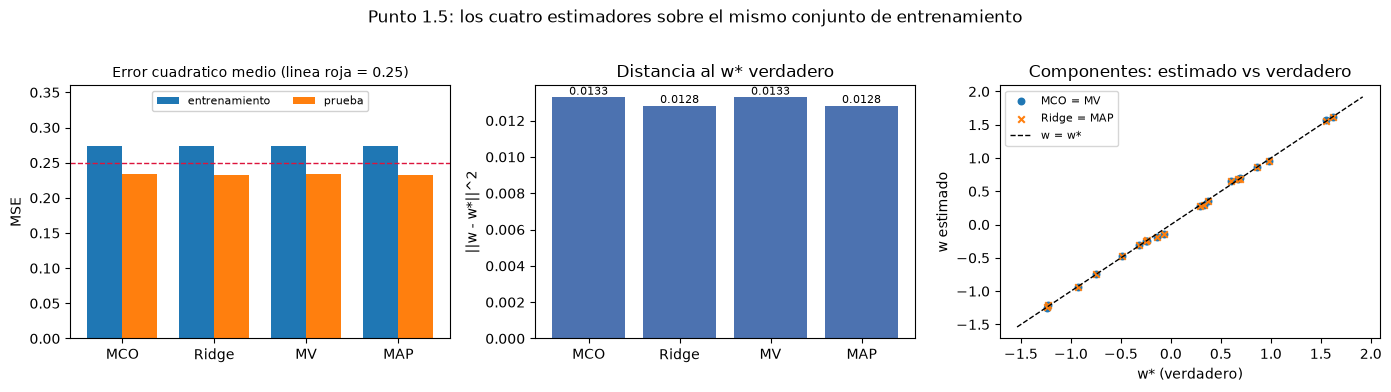

In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 3.8))
pos = np.arange(len(nombres_modelos))
ancho = 0.38

# Panel 1: MSE de entrenamiento y de prueba.
ax1.bar(pos - ancho / 2, mse_ent, ancho, label="entrenamiento")
ax1.bar(pos + ancho / 2, mse_pru, ancho, label="prueba")
ax1.axhline(sigma_eta ** 2, color="crimson", ls="--", lw=1)
ax1.set_xticks(pos, nombres_modelos)
ax1.set_ylabel("MSE")
ax1.set_ylim(0.0, 0.36)
ax1.set_title("Error cuadratico medio (linea roja = 0.25)", fontsize=10)
ax1.legend(fontsize=8, loc="upper center", ncol=2, framealpha=0.9)

# Panel 2: distancia al w* verdadero.
ax2.bar(pos, error_w, color="#4c72b0")
ax2.set_xticks(pos, nombres_modelos)
ax2.set_ylabel("||w - w*||^2")
ax2.set_title("Distancia al w* verdadero")
for k, valor in enumerate(error_w):
    ax2.text(k, valor, f"{valor:.4f}", ha="center", va="bottom", fontsize=8)

# Panel 3: componente a componente, MCO/MV contra ridge/MAP.
ax3.scatter(w_estrella, w_mco, s=22, label="MCO = MV")
ax3.scatter(w_estrella, w_ridge, s=22, marker="x", label="Ridge = MAP")
limites = [np.min(w_estrella) - 0.3, np.max(w_estrella) + 0.3]
ax3.plot(limites, limites, "k--", lw=1, label="w = w*")
ax3.set_xlabel("w* (verdadero)")
ax3.set_ylabel("w estimado")
ax3.set_title("Componentes: estimado vs verdadero")
ax3.legend(fontsize=8)

fig.suptitle("Punto 1.5: los cuatro estimadores sobre el mismo conjunto de entrenamiento", y=1.02)
plt.tight_layout()
plt.show()

### Lectura de los resultados del punto 1.5

| Modelo | MSE entrenamiento | MSE prueba | $\lVert \hat{w} - w^\ast \rVert_2^2$ | $\lVert \hat{w} \rVert_2^2$ |
| --- | --- | --- | --- | --- |
| MCO | 0.2732 | 0.2346 | 0.0133 | 13.3804 |
| Ridge ($\lambda = 1$) | 0.2734 | 0.2320 | 0.0128 | 13.2896 |
| MV | 0.2732 | 0.2346 | 0.0133 | 13.3804 |
| MAP ($\lambda = \sigma_\eta^2/\sigma_w^2 = 1$) | 0.2734 | 0.2320 | 0.0128 | 13.2896 |

**MCO y MV coinciden, como debe ser.** La diferencia entre los dos vectores es $\lVert \hat{w}_{\text{mco}} - \hat{w}_{\text{mv}} \rVert_2 = 1.39 \times 10^{-14}$, es decir, ruido de punto flotante. No es casualidad: en la verosimilitud gaussiana el único término que depende de $w$ es $-\lVert t - \Phi w \rVert_2^2/(2\sigma_\eta^2)$, así que maximizar la verosimilitud y minimizar la suma de residuos al cuadrado son **el mismo problema de optimización** y comparten las ecuaciones normales. Las dos rutas numéricas son distintas (solución directa del sistema $20 \times 20$ frente a `lstsq`, que usa SVD), y esa es justamente la prueba de que el acuerdo es real y no un resultado copiado: con $\operatorname{cond}(\Phi_{\text{ent}}^\top \Phi_{\text{ent}}) = 20.41$ la diferencia queda en el orden del épsilon de máquina amplificado por el condicionamiento.

**Ridge y MAP coinciden, también como debe ser.** $\lVert \hat{w}_{\text{ridge}} - \hat{w}_{\text{map}} \rVert_2 = 0$ exacto, porque $\lambda = 1$ y $\sigma_\eta^2/\sigma_w^2 = 0.25/0.25 = 1$ producen literalmente la misma matriz $\Phi_{\text{ent}}^\top \Phi_{\text{ent}} + I_{20}$ y el mismo término independiente: el prior $\mathcal{N}(0, \sigma_w^2 I)$ con $\sigma_w^2 = \sigma_\eta^2/\lambda$ es exactamente el prior que induce la penalización cuadrática de $\lambda$. Coincidencia esperada, no coincidencia numérica. En la gráfica de componentes se ve como dos nubes de puntos sobre la misma diagonal.

**Por qué MCO/MV y ridge/MAP difieren, y por qué poco.** La diferencia entre ambos pares es $\lVert \hat{w}_{\text{mco}} - \hat{w}_{\text{ridge}} \rVert_2 = 0.0144$ sobre una norma de $\lVert w^\ast \rVert_2 = 3.6483$, es decir $0.4\%$: pequeña, pero real. Ridge encoge el vector ($\lVert \hat{w} \rVert_2^2$ baja de $13.3804$ a $13.2896$ y $\lVert \hat{w} - w^\ast \rVert_2^2$ de $0.0133$ a $0.0128$). El encogimiento es chico porque $\lambda = 1$ es despreciable frente a la escala de $\Phi_{\text{ent}}^\top \Phi_{\text{ent}}$, cuyas entradas son del orden de las 240 filas de entrenamiento. Ahí está la justificación numérica de la discrepancia: **no es un error, es el sesgo que introduce la penalización**, y su tamaño relativo es $\lambda / \lambda_{\max}(\Phi^\top \Phi)$.

**Sobre la magnitud de los MSE.** Los cuatro valores están alrededor de $\sigma_\eta^2 = 0.25$, que es la varianza irreducible del ruido: con 240 y 60 observaciones, el MSE muestral de $\eta^2$ tiene desviación típica $\approx \sigma_\eta^2\sqrt{2/N}$, o sea $0.023$ en entrenamiento y $0.046$ en prueba. La diferencia entre $0.2732$ y $0.2346$ cae dentro de esa variabilidad, y la ligera ventaja de prueba de ridge/MAP ($0.2320$ frente a $0.2346$) es una reducción de varianza, no una mejora estructural: con $Q = 20$, $N_{\text{ent}} = 240$ y una matriz bien condicionada, MCO ya era estable. Con menos datos o con columnas casi colineales, la brecha entre MCO y ridge se agranda y la regularización pasa a ser necesaria, no opcional.

**Un detalle honesto.** El prior del MAP supone $\sigma_w^2 = 0.25$ ($\sigma_w = 0.5$), mientras que el $w^\ast$ simulado tiene $\lVert w^\ast \rVert_2 = 3.6483$, es decir una escala efectiva por componente de $3.6483/\sqrt{20} \approx 0.82$. El prior está entonces **subestimado** respecto de la verdad, y aun así el encogimiento mejoró apenas el error de prueba: la reducción de varianza compensó el sesgo introducido. Si el prior hubiera sido más ancho que la realidad, el mismo $\lambda$ habría costado más sesgo que la varianza ahorrada.

## 2.4. Discrepancia máxima de medias sobre MNIST

**Comparación que se hace aquí.** El enunciado propone comparar MNIST contra Fashion-MNIST y, como referencia, dos particiones disjuntas de cada dataset. En este cuaderno se hace **solo la referencia de MNIST**: se toman 1000 imágenes del conjunto de entrenamiento de MNIST, se permutan con semilla fija y se parten en dos grupos disjuntos de 500; se comparan los **primeros 500** con los **segundos 500**. No se usa Fashion-MNIST ni se usan las etiquetas de clase.

Como ambas muestras salen de la misma distribución, el valor esperado de $\text{MMD}^2$ es 0: el número que se obtiene es la línea base muestral contra la cual se leería cualquier MMD entre distribuciones distintas.

**Representación de las imágenes.** Cada imagen $28 \times 28$ se aplana a un vector de 784 componentes con los píxeles escalados de $\{0, \dots, 255\}$ a $[0, 1]$ mediante $u = \text{píxel}/255$.

**El estimador.** Para un kernel simétrico definido positivo $k$ y dos muestras $\{x_i\}_{i=1}^{n}$, $\{y_j\}_{j=1}^{m}$, el estimador empírico sesgado de $\text{MMD}^2(P_X, P_Y) = \lVert \mu_X - \mu_Y \rVert_{\mathcal{H}_k}^2$ es

$$\widehat{\text{MMD}}^2 = \frac{1}{n^2}\sum_{i=1}^{n}\sum_{j=1}^{n} k(x_i, x_j) + \frac{1}{m^2}\sum_{i=1}^{m}\sum_{j=1}^{m} k(y_i, y_j) - \frac{2}{nm}\sum_{i=1}^{n}\sum_{j=1}^{m} k(x_i, y_j),$$

que en forma matricial, con $\mathbf{1}_n \in \mathbb{R}^n$ el vector de unos, es

$$\widehat{\text{MMD}}^2 = \frac{1}{n^2}\mathbf{1}_n^\top K_{XX}\mathbf{1}_n + \frac{1}{m^2}\mathbf{1}_m^\top K_{YY}\mathbf{1}_m - \frac{2}{nm}\mathbf{1}_n^\top K_{XY}\mathbf{1}_m .$$

**Dimensiones.** Con $n = m = 500$: $K_{XX} \in \mathbb{R}^{500 \times 500}$, $K_{YY} \in \mathbb{R}^{500 \times 500}$ y $K_{XY} \in \mathbb{R}^{500 \times 500}$. Cada producto $\mathbf{1}_n^\top K_{XX}\mathbf{1}_n$ es un escalar: suma de las $500^2$ entradas de $K_{XX}$, así que dividido por $n^2$ es simplemente el promedio de todas sus entradas.

**Kernel gaussiano.** $k(u, v) = \exp\left(-\lVert u - v \rVert_2^2 / (2\sigma^2)\right)$, con un único $\sigma > 0$ para todas las comparaciones.

In [9]:
# MNIST se carga con TensorFlow (unica dependencia de TF en el cuaderno).
(imagenes_entrenamiento, _), _ = tf.keras.datasets.mnist.load_data()
imagenes = imagenes_entrenamiento[:1000]      # primeras 1000 imagenes, (1000, 28, 28)

print("imagenes crudas:", imagenes.shape, imagenes.dtype, " rango:", imagenes.min(), "-", imagenes.max())

# Aplanado a 784 componentes y escalado a [0, 1].
base = imagenes.reshape(1000, 784).astype(np.float64) / 255.0
print("base aplanada:", base.shape, " min:", base.min(), " max:", base.max())

imagenes crudas: (1000, 28, 28) uint8  rango: 0 - 255
base aplanada: (1000, 784)  min: 0.0  max: 1.0


In [10]:
# Particion aleatoria con semilla fija: primeros 500 y segundos 500.
orden = np.random.default_rng(SEMILLA).permutation(1000)

X_mnist = base[orden[:500]]         # (500, 784) primeros 500
Y_mnist = base[orden[500:]]         # (500, 784) segundos 500
grupo_a = imagenes[orden[:500]]     # (500, 28, 28) para visualizar
grupo_b = imagenes[orden[500:]]

print("X_mnist:", X_mnist.shape, " Y_mnist:", Y_mnist.shape)
print("filas compartidas entre los dos grupos:", len(np.intersect1d(orden[:500], orden[500:])))

X_mnist: (500, 784)  Y_mnist: (500, 784)
filas compartidas entre los dos grupos: 0


### Qué se está comparando

Ocho imágenes al azar de cada grupo, sin sus etiquetas: el punto 2.4 pide comparar las distribuciones de píxeles, no las clases. A simple vista los dos grupos son indistinguibles, que es exactamente la hipótesis que el $\text{MMD}^2$ debe poner a prueba.

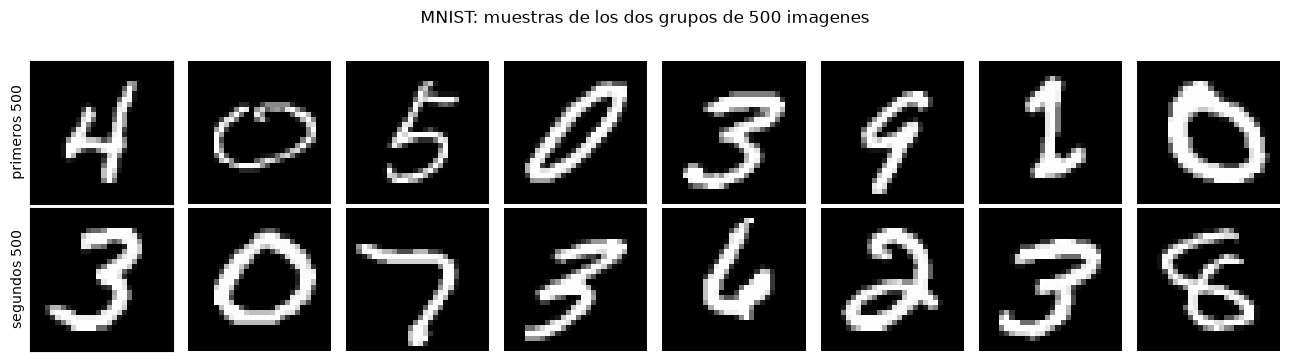

In [11]:
fig, ejes = plt.subplots(2, 8, figsize=(13, 3.6))

for k in range(8):
    ejes[0, k].imshow(grupo_a[k], cmap="gray")
    ejes[0, k].axis("off")
    ejes[1, k].imshow(grupo_b[k], cmap="gray")
    ejes[1, k].axis("off")

ejes[0, 0].set_ylabel("primeros 500", fontsize=10)
ejes[1, 0].set_ylabel("segundos 500", fontsize=10)
for eje in (ejes[0, 0], ejes[1, 0]):
    eje.axis("on")
    eje.set_xticks([])
    eje.set_yticks([])

fig.suptitle("MNIST: muestras de los dos grupos de 500 imagenes", y=1.0)
plt.tight_layout()
plt.show()

## 2.4.1. Elección del ancho de banda $\sigma$ por la mediana de distancias

Se combinan las 1000 imágenes en una sola matriz $A \in \mathbb{R}^{1000 \times 784}$ y se calculan todas las distancias euclidianas entre pares de imágenes distintas,

$$d_{ij} = \lVert a_i - a_j \rVert_2, \qquad i < j,$$

y se define $\sigma$ como la **mediana** de esos $\binom{1000}{2} = 499{,}500$ valores. Es la heurística de la mediana: si $\sigma$ fuera mucho menor que las distancias típicas, $k(u, v) \approx 0$ para casi todo par y el kernel no distingue nada; si fuera mucho mayor, $k(u, v) \approx 1$ para todo par y el MMD se anula. La mediana deja el kernel en una escala donde las diferencias entre imágenes se resuelven.

Las distancias al cuadrado se obtienen con la identidad $\lVert a_i - a_j \rVert_2^2 = \lVert a_i \rVert_2^2 + \lVert a_j \rVert_2^2 - 2\,a_i^\top a_j$, es decir con un producto matricial $A A^\top$ seguido de dos sumas de normas.

In [12]:
A = np.vstack([X_mnist, Y_mnist])                 # (1000, 784)
normas = np.sum(A ** 2, axis=1)                   # (1000,)

# d2[i, j] = ||a_i - a_j||^2  ->  (1000, 1000)
d2 = normas[:, None] + normas[None, :] - 2.0 * (A @ A.T)
d2 = np.maximum(d2, 0.0)                          # corrige -1e-15 por redondeo

filas, columnas_ = np.triu_indices(1000, k=1)     # pares i < j, sin la diagonal
distancias = np.sqrt(d2[filas, columnas_])
sigma = np.median(distancias)

print("numero de pares distintos:", distancias.size)
print("distancia minima:", round(distancias.min(), 4), " maxima:", round(distancias.max(), 4))
print("mediana (sigma) :", round(sigma, 4))
print("sigma^2         :", round(sigma ** 2, 4))

numero de pares distintos: 499500
distancia minima: 1.1742  maxima: 14.8922
mediana (sigma) : 10.1291
sigma^2         : 102.5989


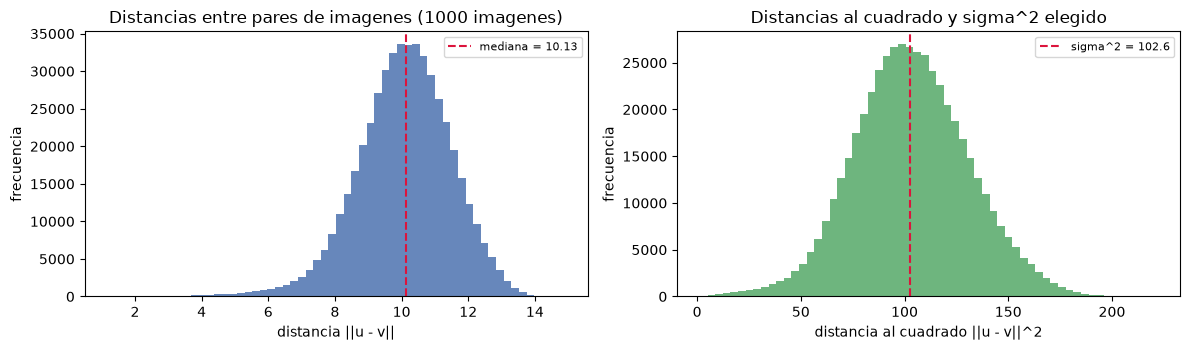

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))

# Histograma de distancias entre pares, con la mediana elegida.
ax1.hist(distancias, bins=60, color="#4c72b0", alpha=0.85)
ax1.axvline(sigma, color="crimson", ls="--", lw=1.5, label=f"mediana = {sigma:.2f}")
ax1.set_xlabel("distancia ||u - v||")
ax1.set_ylabel("frecuencia")
ax1.set_title("Distancias entre pares de imagenes (1000 imagenes)")
ax1.legend(fontsize=8)

# El mismo histograma en escala logaritmica de la distancia al cuadrado.
ax2.hist(np.sqrt(d2[filas, columnas_]) ** 2, bins=60, color="#55a868", alpha=0.85)
ax2.axvline(sigma ** 2, color="crimson", ls="--", lw=1.5, label=f"sigma^2 = {sigma ** 2:.1f}")
ax2.set_xlabel("distancia al cuadrado ||u - v||^2")
ax2.set_ylabel("frecuencia")
ax2.set_title("Distancias al cuadrado y sigma^2 elegido")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 2.4.2. Matrices de Gram y $\widehat{\text{MMD}}^2$ entre los dos grupos

Con el mismo $\sigma$ se calculan las tres matrices de Gram y se aplica el estimador matricial. Como $\mathbf{1}^\top K \mathbf{1} / n^2$ es el promedio de todas las entradas de $K$, el cálculo se reduce a tres promedios.

In [14]:
K = np.exp(-d2 / (2.0 * sigma ** 2))    # (1000, 1000): kernel gaussiano

K_xx = K[:500, :500]                     # (500, 500) primeros 500 contra si mismos
K_yy = K[500:, 500:]                     # (500, 500) segundos 500 contra si mismos
K_xy = K[:500, 500:]                     # (500, 500) primeros 500 contra segundos 500

uno_xx = np.ones(500) @ K_xx @ np.ones(500)    # 1^T K_xx 1  (escalar)
uno_yy = np.ones(500) @ K_yy @ np.ones(500)    # 1^T K_yy 1  (escalar)
uno_xy = np.ones(500) @ K_xy @ np.ones(500)    # 1^T K_xy 1  (escalar)

n = m = 500
mmd2 = uno_xx / n ** 2 + uno_yy / m ** 2 - 2.0 * uno_xy / (n * m)

print("K    :", K.shape)
print("K_xx :", K_xx.shape, " K_yy :", K_yy.shape, " K_xy :", K_xy.shape)
print("1^T K_xx 1 / n^2          =", round(uno_xx / n ** 2, 6))
print("1^T K_yy 1 / m^2          =", round(uno_yy / m ** 2, 6))
print("2 * 1^T K_xy 1 / (n * m)  =", round(2.0 * uno_xy / (n * m), 6))
print()
print("MMD^2 (sesgado) =", mmd2)
print("MMD             =", np.sqrt(max(mmd2, 0.0)))

K    : (1000, 1000)
K_xx : (500, 500)  K_yy : (500, 500)  K_xy : (500, 500)
1^T K_xx 1 / n^2          = 0.615692
1^T K_yy 1 / m^2          = 0.606084
2 * 1^T K_xy 1 / (n * m)  = 1.219834

MMD^2 (sesgado) = 0.0019416220728127875
MMD             = 0.044063840876764106


### Las tres matrices de Gram

Los bloques $K_{XX}$ y $K_{YY}$ son las similitudes internas de cada grupo y el bloque cruzado $K_{XY}$ mide la similitud entre grupos. Si las dos muestras vinieran de la misma distribución, los tres bloques deberían verse estadísticamente iguales: eso es lo que el $\widehat{\text{MMD}}^2$ resume en un número.

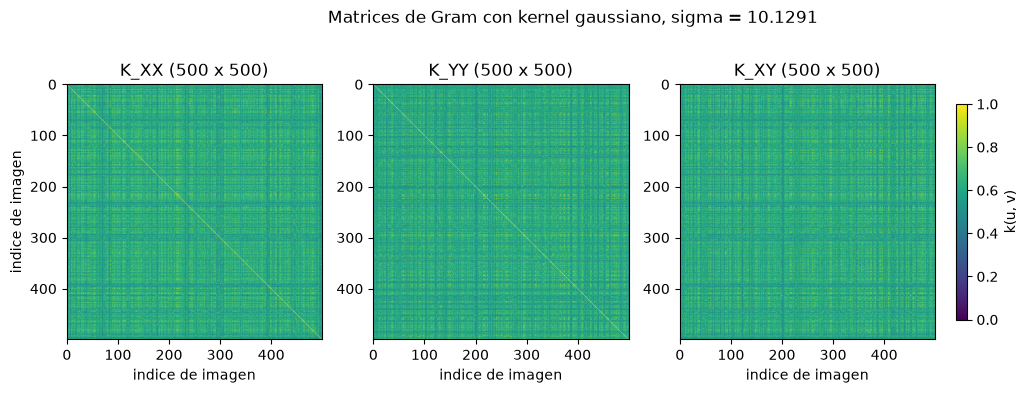

In [15]:
fig, ejes = plt.subplots(1, 3, figsize=(13.5, 4))

for k, (eje, matriz, titulo) in enumerate(zip(
    ejes,
    (K_xx, K_yy, K_xy),
    ("K_XX (500 x 500)", "K_YY (500 x 500)", "K_XY (500 x 500)"),
)):
    imagen = eje.imshow(matriz, cmap="viridis", vmin=0.0, vmax=1.0)
    eje.set_title(titulo)
    eje.set_xlabel("indice de imagen")
    if k == 0:
        eje.set_ylabel("indice de imagen")

fig.colorbar(imagen, ax=ejes, shrink=0.7, pad=0.02, label="k(u, v)")
fig.suptitle(f"Matrices de Gram con kernel gaussiano, sigma = {sigma:.4f}", y=1.0)
plt.show()

In [16]:
# Comprobacion: la formula matricial debe coincidir con los tres promedios directos.
mmd2_directo = K_xx.mean() + K_yy.mean() - 2.0 * K_xy.mean()
print("MMD^2 matricial:", mmd2)
print("MMD^2 por promedios:", mmd2_directo)
print("diferencia:", abs(mmd2 - mmd2_directo))

MMD^2 matricial: 0.0019416220728127875
MMD^2 por promedios: 0.0019416220728123434
diferencia: 4.440892098500626e-16


## 2.4.3. Influencia del ancho de banda

Se repite el cálculo con $\sigma$ multiplicado por $0.25$, $0.5$, $1$, $2$ y $4$. La misma $\sigma$ escala se usa en todas las comparaciones del cuaderno; lo que cambia aquí es solo el factor, para ver cómo responde el estimador.

In [17]:
factores = [0.25, 0.5, 1.0, 2.0, 4.0]
mmd2_por_factor = []

print(f"{'factor':>7}{'sigma':>10}{'MMD^2':>14}")
for factor in factores:
    s = factor * sigma
    K_f = np.exp(-d2 / (2.0 * s ** 2))
    valor = K_f[:500, :500].mean() + K_f[500:, 500:].mean() - 2.0 * K_f[:500, 500:].mean()
    mmd2_por_factor.append(valor)
    print(f"{factor:7.2f}{s:10.4f}{valor:14.6f}")

 factor     sigma         MMD^2
   0.25    2.5323      0.004148
   0.50    5.0646      0.003832
   1.00   10.1291      0.001942
   2.00   20.2582      0.000606
   4.00   40.5165      0.000161


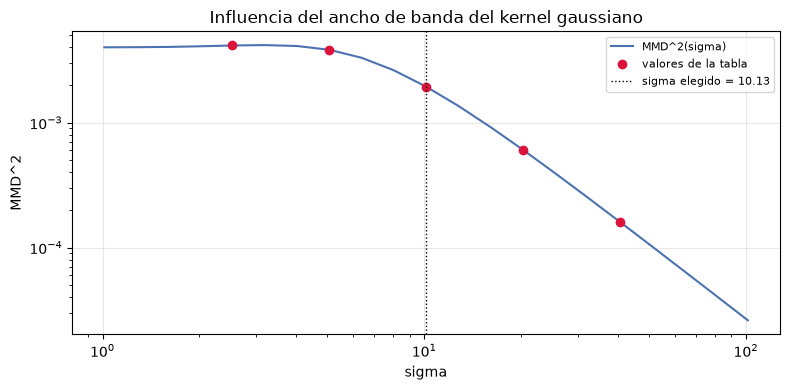

In [18]:
# Curva completa de MMD^2 en funcion de sigma, en escala logaritmica.
factores_finos = np.logspace(-1.0, 1.0, 21)
curva = []
for factor in factores_finos:
    s = factor * sigma
    K_f = np.exp(-d2 / (2.0 * s ** 2))
    curva.append(K_f[:500, :500].mean() + K_f[500:, 500:].mean() - 2.0 * K_f[:500, 500:].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.array(factores_finos) * sigma, curva, "-", color="#4c72b0", label="MMD^2(sigma)")
ax.plot(np.array(factores) * sigma, mmd2_por_factor, "o", color="crimson", label="valores de la tabla")
ax.axvline(sigma, color="black", ls=":", lw=1, label=f"sigma elegido = {sigma:.2f}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("sigma")
ax.set_ylabel("MMD^2")
ax.set_title("Influencia del ancho de banda del kernel gaussiano")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.4.4. Variabilidad muestral

$\widehat{\text{MMD}}^2$ es un estadístico: cambia si cambian las 1000 imágenes o la partición. Se repite la comparación con cinco particiones distintas de las mismas 1000 imágenes, manteniendo el mismo $\sigma$.

In [19]:
semillas = [1, 2, 3, 4, 5]
mmd2_por_semilla = []

print(f"{'semilla':>8}{'MMD^2':>14}")
for semilla in semillas:
    orden_s = np.random.default_rng(semilla).permutation(1000)
    B = base[orden_s]                                  # (1000, 784)
    n2 = np.sum(B ** 2, axis=1)
    dd2 = np.maximum(n2[:, None] + n2[None, :] - 2.0 * (B @ B.T), 0.0)
    K_s = np.exp(-dd2 / (2.0 * sigma ** 2))
    valor = K_s[:500, :500].mean() + K_s[500:, 500:].mean() - 2.0 * K_s[:500, 500:].mean()
    mmd2_por_semilla.append(valor)
    print(f"{semilla:8d}{valor:14.6f}")

print()
print("media :", round(np.mean(mmd2_por_semilla), 6))
print("desv. :", round(np.std(mmd2_por_semilla, ddof=1), 6))
print("minimo:", round(np.min(mmd2_por_semilla), 6), " maximo:", round(np.max(mmd2_por_semilla), 6))

 semilla         MMD^2
       1      0.001886
       2      0.002142
       3      0.001049
       4      0.001657
       5      0.001625

media : 0.001672
desv. : 0.000405
minimo: 0.001049  maximo: 0.002142


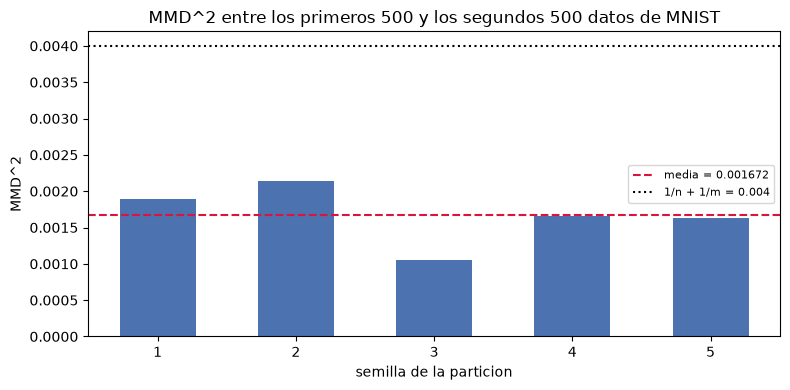

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar([str(s) for s in semillas], mmd2_por_semilla, color="#4c72b0", width=0.55)
ax.axhline(np.mean(mmd2_por_semilla), color="crimson", ls="--", lw=1.5,
           label=f"media = {np.mean(mmd2_por_semilla):.6f}")
ax.axhline(1 / 500 + 1 / 500, color="black", ls=":", lw=1.5,
           label="1/n + 1/m = 0.004")
ax.set_xlabel("semilla de la particion")
ax.set_ylabel("MMD^2")
ax.set_title("MMD^2 entre los primeros 500 y los segundos 500 datos de MNIST")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lectura de los resultados del punto 2.4

$\widehat{\text{MMD}}^2$ entre los primeros 500 y los segundos 500 datos de MNIST, con $\sigma = 10.1291$:

| Término | Valor |
| --- | --- |
| $\mathbf{1}^\top K_{XX}\mathbf{1}/n^2$ (promedio de $K_{XX}$) | 0.615692 |
| $\mathbf{1}^\top K_{YY}\mathbf{1}/m^2$ (promedio de $K_{YY}$) | 0.606084 |
| $2\,\mathbf{1}^\top K_{XY}\mathbf{1}/(nm)$ (promedio de $K_{XY}$, duplicado) | 1.219834 |
| $\widehat{\text{MMD}}^2$ | **0.001942** |
| $\widehat{\text{MMD}}$ | 0.044064 |

La fórmula matricial y el cálculo por promedios directos coinciden hasta $4.4 \times 10^{-16}$: es la misma cuenta, como debe ser, porque $\mathbf{1}^\top K \mathbf{1}/n^2$ es el promedio de las $500^2$ entradas de $K$.

**Por qué el valor es chico y por qué no es exactamente cero.** Los dos grupos son mitades de las mismas 1000 imágenes, así que $P_X = P_Y$ y $\text{MMD}^2$ poblacional vale 0. El estimador es **sesgado**: al reemplazar $\mathbb{E}[k(X, X')]$ por promedios dentro de la muestra, cada término incluye los pares $i = j$, y

$$\mathbb{E}\big[\widehat{\text{MMD}}^2\big] = \text{MMD}^2 + \frac{1}{n}\big(\mathbb{E}[k(X,X)] - \mathbb{E}[k(X,X')]\big) + \frac{1}{m}\big(\mathbb{E}[k(Y,Y)] - \mathbb{E}[k(Y,Y')]\big).$$

Como $k(x,x) = 1$ y el promedio fuera de la diagonal es $\approx 0.61$, el sesgo esperado es $\approx (1 - 0.61)/500 + (1 - 0.61)/500 \approx 0.0016$, del mismo orden que el $0.001942$ observado. La diferencia restante es la variabilidad muestral de esta partición concreta. **El valor no prueba que las distribuciones coincidan ni que difieran:** es la línea base sesgada de "dos muestras de la misma distribución".

**Influencia del ancho de banda.** La tabla y la curva muestran los dos extremos:

- $\sigma$ muy chico ($0.25\sigma$): cada $k(u,v)$ se concentra en los pares casi idénticos y el cálculo queda dominado por la diagonal, donde $k(u,u) = 1$. Los pares distintos no aportan cero, pero como los dos grupos salen de la misma distribución se cancelan entre el promedio propio de cada grupo y el cruzado, y sobrevive $1/n + 1/m = 0.004$, que es el valor observado $0.004148$. En ese régimen el kernel ya casi no compara imágenes distintas: el número es casi puro sesgo de la diagonal.
- $\sigma$ muy grande ($4\sigma$): $k(u,v) \to 1$ para todo par y todas las entradas de $K$ tienden a 1, con lo que $\widehat{\text{MMD}}^2 \to 0$ ($0.000161$). El kernel promedia todo y borra las diferencias.

Entre esos dos extremos el estimador tiene un máximo en alguna escala intermedia; la heurística de la mediana ($\sigma = 10.1291$, con distancias entre imágenes de $1.17$ a $14.89$) cae en una zona razonable: $2\sigma^2 = 205.2$, comparable al cuadrado de las distancias típicas ($\sigma^2 = 102.6$, mediana de $\lVert u - v \rVert^2$). Por eso el mismo $\sigma$ se usa en todas las comparaciones del cuaderno: cambiar el ancho de banda cambia el número aunque las distribuciones no cambien.

**Variabilidad muestral.** Las cinco particiones distintas dan $0.001886$, $0.002142$, $0.001049$, $0.001657$ y $0.001625$: el mismo orden que el sesgo calculado y una dispersión de casi un factor 2. Con 500 imágenes por grupo, un $\widehat{\text{MMD}}^2$ aislado de este tamaño no distingue "misma distribución" de "distribuciones parecidas". Para eso haría falta un **contraste formal** ausente en este punto: un test de permutación (rebarajar las 1000 imágenes y comparar el valor observado con la distribución nula) o la distribución asintótica nula del estadístico. Sin ese contraste, el número se reporta como descriptivo y la conclusión queda limitada a: las dos mitades de MNIST se parecen tanto como se espera de dos muestras de la misma distribución, y ese $\approx 0.002$ es la referencia contra la cual se leería un MMD entre MNIST y Fashion-MNIST.

## Resumen

| Punto | Qué quedó verificado |
| --- | --- |
| 1.5 | Los cuatro estimadores ajustados solo con entrenamiento; MCO y MV coinciden y ridge y MAP coinciden, con las diferencias numéricas explicadas y las tres gráficas de comparación. |
| 2.4 | $\widehat{\text{MMD}}^2$ entre los primeros 500 y los segundos 500 datos de MNIST, con $\sigma$ elegido por la mediana de distancias, más las muestras, las tres matrices de Gram, la influencia del ancho de banda y la variabilidad entre particiones. |

**Herramientas.** TensorFlow solo carga MNIST (`tf.keras.datasets.mnist`); los estimadores, el kernel gaussiano y el $\text{MMD}^2$ son NumPy; las cinco figuras son matplotlib. No se usa scikit-learn en ninguna parte.

**Límite de interpretación.** Un valor de $\widehat{\text{MMD}}^2$ por sí solo no es un contraste de hipótesis: el estimador sesgado es positivo incluso cuando $P_X = P_Y$, porque $\mathbb{E}[\widehat{\text{MMD}}^2] = \text{MMD}^2 + \text{término de sesgo}$ con el término de sesgo $\approx (\mathbb{E}[k(X,X)] + \mathbb{E}[k(Y,Y)])/n$ para $n = m$. Para afirmar que dos distribuciones difieren haría falta un procedimiento formal, por ejemplo un test de permutación o la distribución asintótica nula, que no forma parte de este punto.